# Neural Networks on the Census Income (Adult) Dataset

Goal: predict whether a person earns **>50K** per year.
We train **three architectures** with different numbers of hidden layers and nodes, draw each one, and look at the edge weights to see which inputs each network relies on.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

## 1. Load the data
We keep 7 simple inputs so every input node can be labeled on the diagrams.
`sex` and `marital_status` become yes/no columns (`is_male`, `married`).

In [20]:
cols = ["age", "workclass", "fnlwgt", "education", "education_num", "marital_status",
        "occupation", "relationship", "race", "sex", "capital_gain", "capital_loss",
        "hours_per_week", "native_country", "income"]
df = pd.read_csv("data/adult.data", names=cols, skipinitialspace=True, na_values="?").dropna()

# target: 1 = earns >50K, 0 = earns <=50K
df["income"] = (df["income"] == ">50K").astype(int)

# two simple yes/no features
df["is_male"] = (df["sex"] == "Male").astype(int)
df["married"] = (df["marital_status"].str.startswith("Married")).astype(int)

features = ["age", "education_num", "hours_per_week", "capital_gain",
            "capital_loss", "is_male", "married"]
X = df[features]
y = df["income"]
print(X.shape, "| share earning >50K:", round(y.mean(), 3))
X.head()

(30162, 7) | share earning >50K: 0.249


,age,education_num,hours_per_week,capital_gain,capital_loss,is_male,married
0,39,13,40,2174,0,1,0
1,50,13,13,0,0,1,1
2,38,9,40,0,0,1,0
3,53,7,40,0,0,1,1
4,28,13,40,0,0,0,1


## 2. Train/test split and scaling
Neural networks are sensitive to feature scale, so we standardize the inputs (fit on the training data only).

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

## 3. Train three architectures
| Name | Hidden layers |
|---|---|
| A | 1 layer: 4 nodes |
| B | 2 layers: 8, 4 nodes |
| C | 3 layers: 12, 8, 4 nodes |

In [22]:
architectures = {
    "A: 1 hidden layer (4)":          (4,),
    "B: 2 hidden layers (8, 4)":      (8, 4),
    "C: 3 hidden layers (12, 8, 4)":  (12, 8, 4),
}

models = {}
for name, layers in architectures.items():
    mlp = MLPClassifier(hidden_layer_sizes=layers, max_iter=1000, random_state=42)
    mlp.fit(X_train_s, y_train)
    models[name] = mlp

### How well does each network do?
Accuracy alone can be misleading here because only ~25% of people earn >50K.
So we also look at **precision**, **recall** and **F1** for the >50K class.

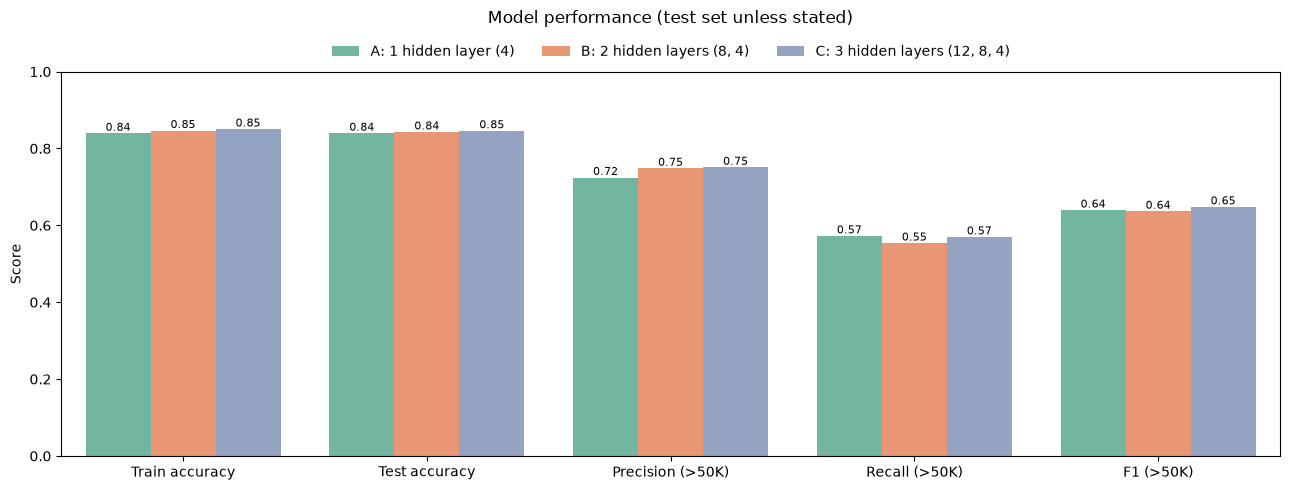

In [23]:
rows = []
for name, mlp in models.items():
    pred_train = mlp.predict(X_train_s)
    pred_test  = mlp.predict(X_test_s)
    rows += [
        {"Model": name, "Metric": "Train accuracy",    "Score": accuracy_score(y_train, pred_train)},
        {"Model": name, "Metric": "Test accuracy",     "Score": accuracy_score(y_test, pred_test)},
        {"Model": name, "Metric": "Precision (>50K)",  "Score": precision_score(y_test, pred_test)},
        {"Model": name, "Metric": "Recall (>50K)",     "Score": recall_score(y_test, pred_test)},
        {"Model": name, "Metric": "F1 (>50K)",         "Score": f1_score(y_test, pred_test)},
    ]
metrics = pd.DataFrame(rows)

plt.figure(figsize=(13, 5))
ax = sns.barplot(data=metrics, x="Metric", y="Score", hue="Model", palette="Set2")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)
ax.set_ylim(0, 1)
ax.set_xlabel("")
ax.set_title("Model performance (test set unless stated)", pad=35)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3, frameon=False)
plt.tight_layout()
plt.show()

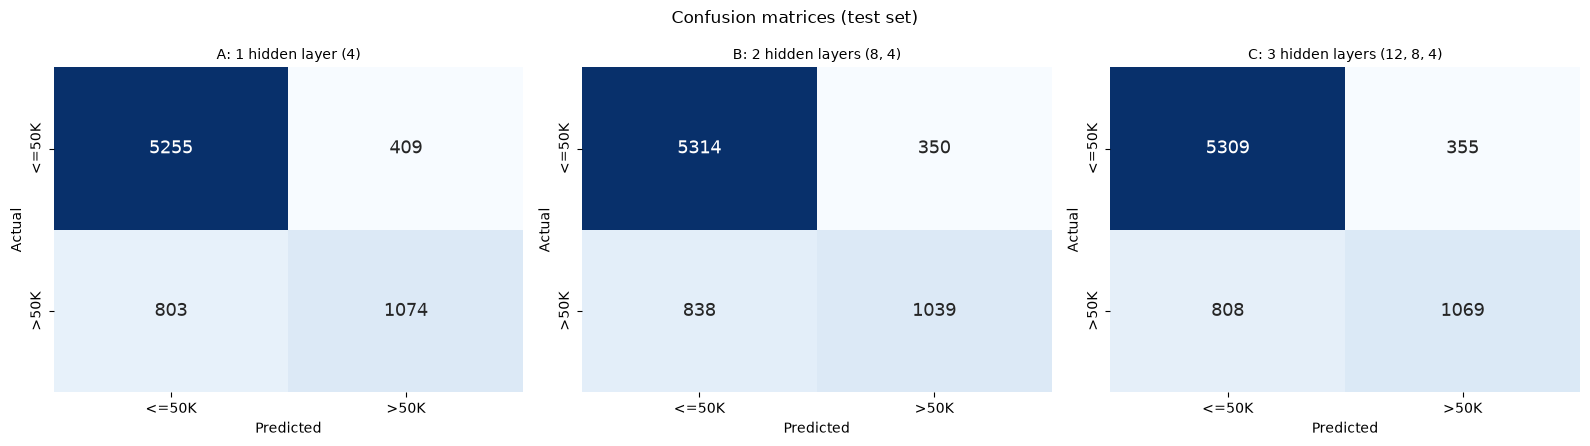

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
labels = ["<=50K", ">50K"]
for ax, (name, mlp) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, mlp.predict(X_test_s))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=labels, yticklabels=labels, annot_kws={"size": 13})
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.set_title(name, fontsize=10)
plt.suptitle("Confusion matrices (test set)")
plt.tight_layout()
plt.show()

## 4. Visualize each architecture
- **Blue** edge = positive weight, **red** edge = negative weight
- Thicker / darker edge = larger |weight|
- Input nodes are labeled with the feature names

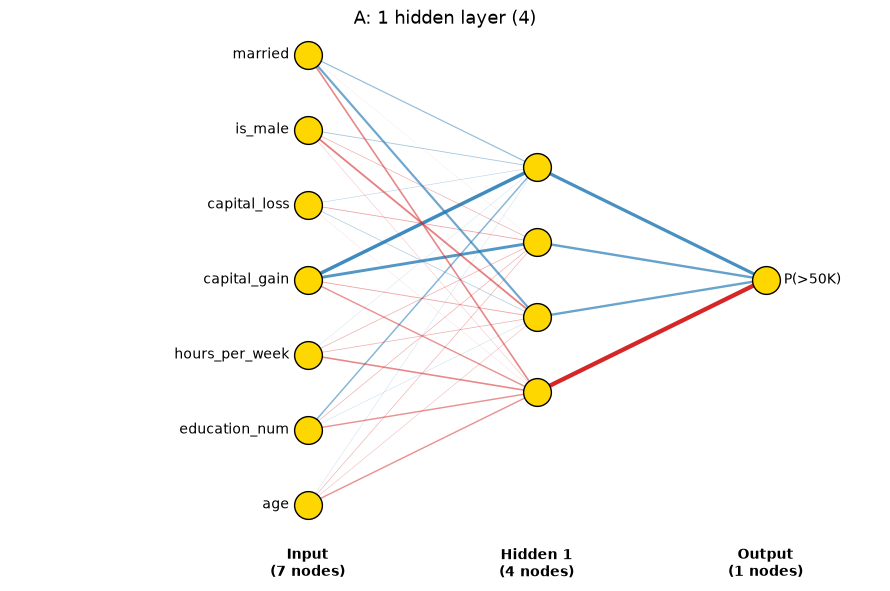

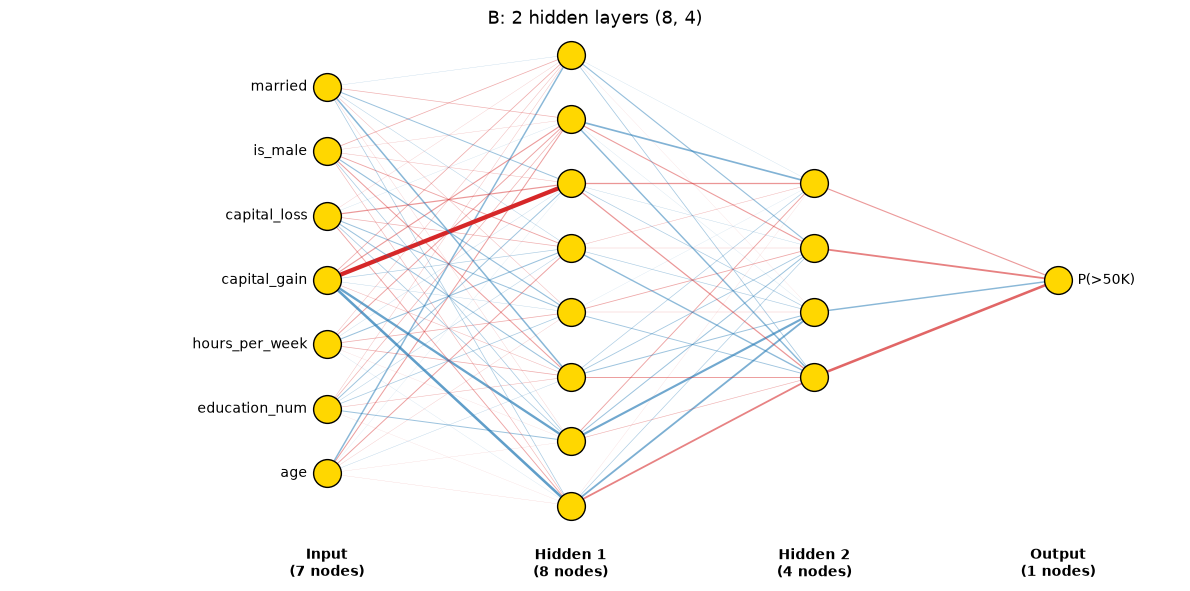

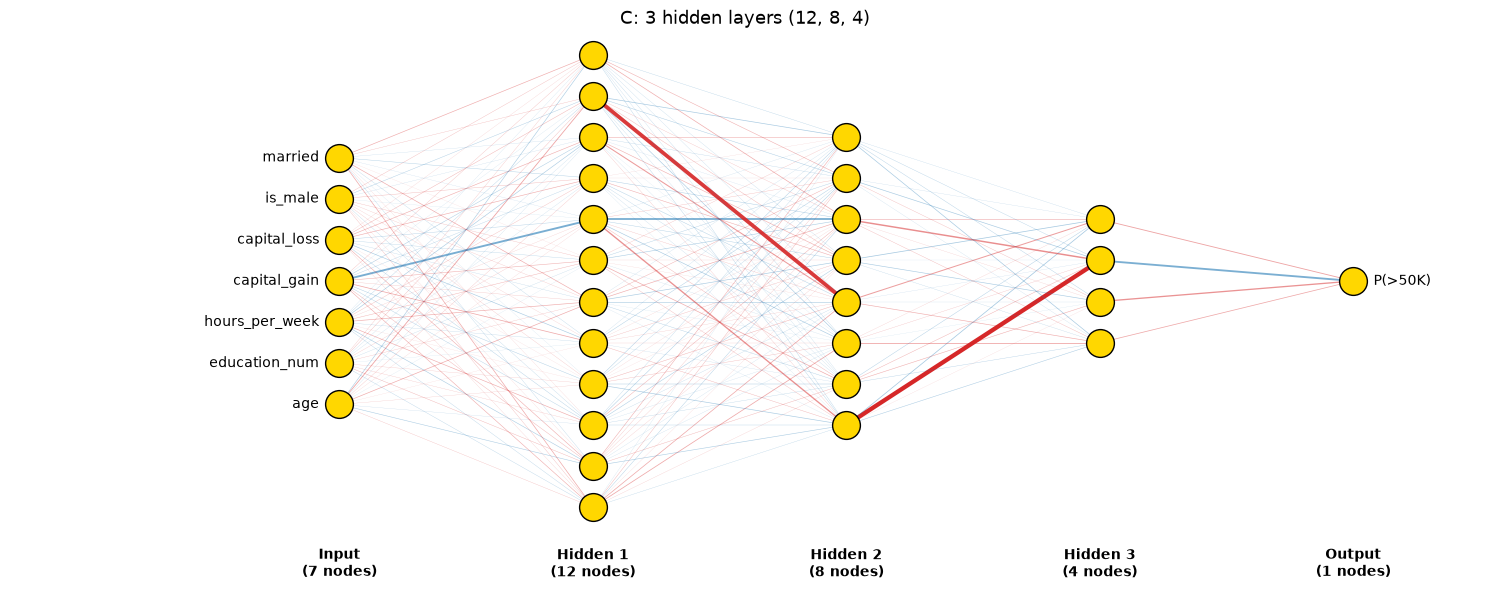

In [25]:
def draw_network(mlp, feature_names, title):
    layer_sizes = [mlp.coefs_[0].shape[0]] + [w.shape[1] for w in mlp.coefs_]
    max_size = max(layer_sizes)

    # (x, y) position of every node, centered vertically
    pos = []
    for L, n in enumerate(layer_sizes):
        ys = np.linspace(0, 1, n) if n > 1 else [0.5]
        offset = (max_size - n) / (2 * max_size)
        pos.append([(L, offset + y_ * (n - 1) / max_size) for y_ in ys])

    fig, ax = plt.subplots(figsize=(3 * len(layer_sizes), 6))
    w_max = max(np.abs(w).max() for w in mlp.coefs_)

    # edges
    for L, W in enumerate(mlp.coefs_):
        for i in range(W.shape[0]):
            for j in range(W.shape[1]):
                w = W[i, j]
                (x1, y1), (x2, y2) = pos[L][i], pos[L + 1][j]
                ax.plot([x1, x2], [y1, y2],
                        color="tab:blue" if w > 0 else "tab:red",
                        linewidth=3 * abs(w) / w_max + 0.1,
                        alpha=0.3 + 0.7 * abs(w) / w_max, zorder=1)
    # nodes
    for layer in pos:
        for (x, y_) in layer:
            ax.scatter(x, y_, s=400, color="gold", edgecolor="black", zorder=2)

    # labels
    for i, name in enumerate(feature_names):
        x, y_ = pos[0][i]
        ax.text(x - 0.08, y_, name, ha="right", va="center", fontsize=10)
    x, y_ = pos[-1][0]
    ax.text(x + 0.08, y_, "P(>50K)", ha="left", va="center", fontsize=10)

    names = ["Input"] + [f"Hidden {k+1}" for k in range(len(layer_sizes) - 2)] + ["Output"]
    for L, n in enumerate(names):
        ax.text(L, -0.08, f"{n}\n({layer_sizes[L]} nodes)", ha="center", va="top",
                fontsize=10, weight="bold")

    ax.set_title(title, fontsize=13)
    ax.set_xlim(-1.3, len(layer_sizes) - 0.5)
    ax.axis("off")
    plt.tight_layout()
    plt.show()

for name, mlp in models.items():
    draw_network(mlp, features, name)

**What I see in the diagrams**

Network A is small enough that you can actually follow it by eye. The thickest lines leaving the inputs come from `capital_gain`, and they feed two hidden nodes that both push the output toward ">50K" (blue lines into the output). One hidden node is the opposite: almost all of its incoming edges are red, and it connects to the output with the thickest red line in the picture. Since a hidden node only fires when its total input is positive, all those red edges mean it switches on when someone is *below average* on age, education, hours and marital status. Then it pushes the prediction toward "<=50K". So it acts like a "probably low income" detector. Another node gets a strong blue line from `married`, which matches the common pattern that married people in this dataset are much more likely to earn over 50K.

Networks B and C are a different story. With 8 and then 12 nodes in the first layer, most edges are thin and faint, and the strong ones are scattered around. You can still spot `capital_gain` with one of the thickest edges in each, but it's very hard to trace how any single input ends up affecting the output. The extra nodes didn't buy much accuracy, but they cost a lot of readability.

## 5. First-layer weights as a heatmap
Row = input feature, column = hidden neuron. Each column shows what that neuron "looks at", like a small learned rule.

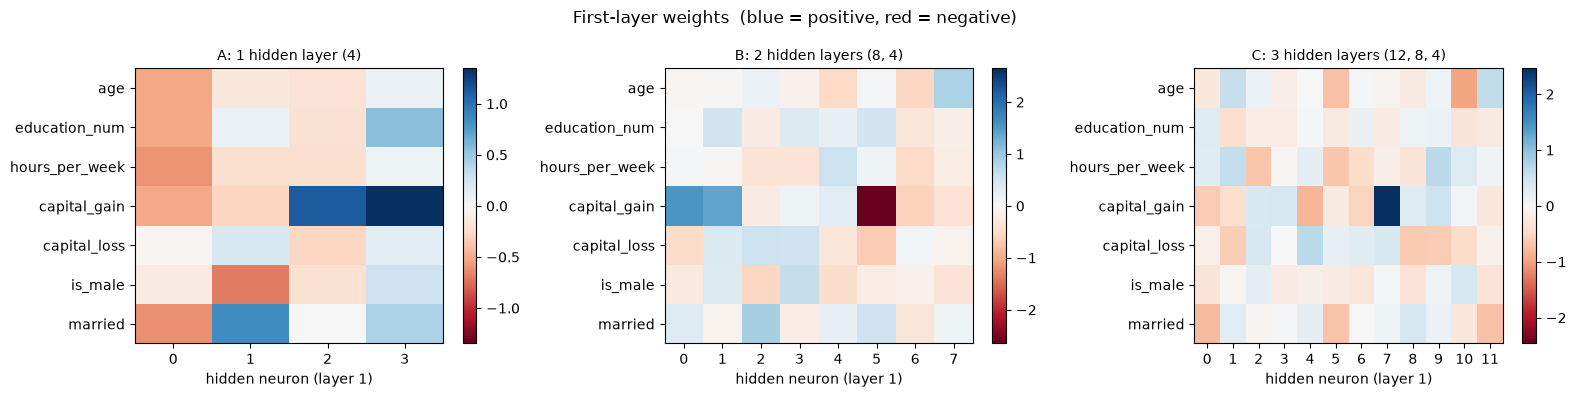

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (name, mlp) in zip(axes, models.items()):
    W = mlp.coefs_[0]
    lim = np.abs(W).max()
    im = ax.imshow(W, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(features)))
    ax.set_yticklabels(features)
    ax.set_xticks(range(W.shape[1]))
    ax.set_xlabel("hidden neuron (layer 1)")
    ax.set_title(name, fontsize=10)
    fig.colorbar(im, ax=ax)
plt.suptitle("First-layer weights  (blue = positive, red = negative)")
plt.tight_layout()
plt.show()

**What I see in the heatmaps**

For network A each column is easy to read:
- **Neuron 0** is light red across the board, so it reacts to people who are below average on most things (the "low income" node from the diagram).
- **Neuron 1** is blue for `married` but red for `is_male`, so it fires mostly for married women. That's a small group, but in this data married women ("wife") earn >50K at a much higher rate than women overall, so the network seems to have carved out a node just for them.
- **Neurons 2 and 3** are dark blue on `capital_gain`. Neuron 3 also leans a bit positive on education and being married. These are the "high income" nodes.

In B and C, almost every cell is pale, and there's usually just one strong cell per column. The darkest cells in both are still in the `capital_gain` row: deep red in B (neuron 5) and deep blue in C (neuron 7). The sign alone doesn't tell you which way the effect goes in the end, because the later layers can flip it. But it confirms that capital gain is the one input every network latches onto. The other features get spread thinly across many nodes, which is why the deeper networks are so much harder to interpret than network A.

## 6. Which inputs does each network rely on?
Importance of a feature = sum of |weights| leaving that input node, normalized so they add up to 1.

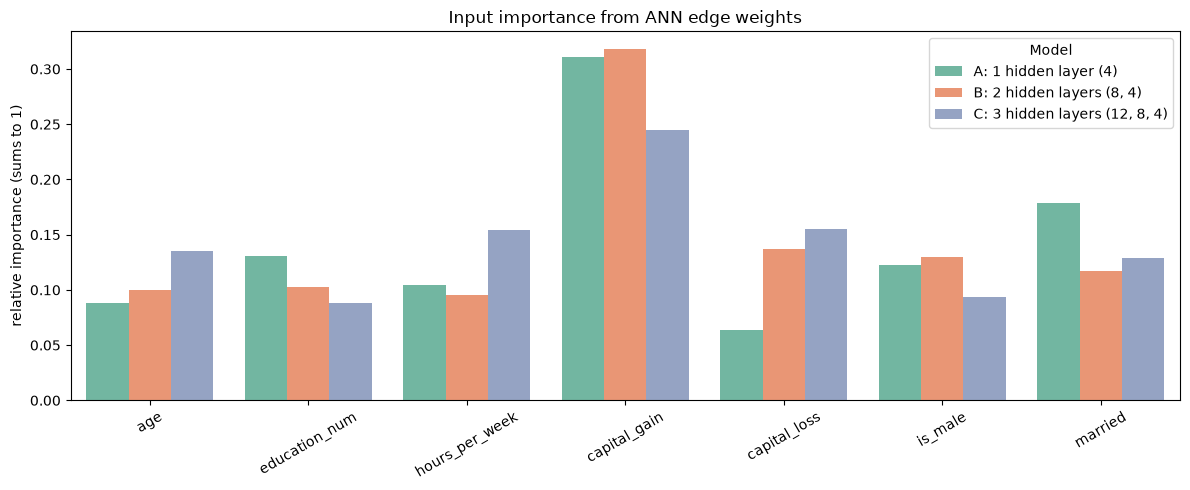

In [27]:
def input_weight_importance(mlp):
    s = np.abs(mlp.coefs_[0]).sum(axis=1)
    return s / s.sum()

importance = pd.DataFrame({name: input_weight_importance(m) for name, m in models.items()},
                          index=features)
imp_long = importance.reset_index().melt(id_vars="index", var_name="Model", value_name="Importance")

plt.figure(figsize=(12, 5))
ax = sns.barplot(data=imp_long, x="index", y="Importance", hue="Model", palette="Set2")
ax.set_xlabel("")
ax.set_ylabel("relative importance (sums to 1)")
ax.set_title("Input importance from ANN edge weights")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 7. Discussion

**Does a bigger network help?** Not by much. Going from one hidden layer with 4 nodes to three layers with 12, 8 and 4 nodes only pushed test accuracy from about 83.9% to 84.6%. The biggest network also needed about four times as many training iterations (212 vs. 50) to converge. Since we only have 7 inputs, there isn't a lot of hidden structure for extra layers to find, and the small network already picks up most of what's there. Train and test accuracy stay very close for all three, so none of them is badly overfitting. The gap does widen a little as the networks get bigger, which is the usual sign that more capacity starts going toward memorizing noise.

**The catch with accuracy.** Around 75% of people in the data earn <=50K, so a model that always guessed "<=50K" would already be right about 75% of the time. Recall for the >50K group tells a more honest story: every network only catches around 55–57% of the high earners. The confusion matrices show the same thing. The models rarely flag a low earner as high-income, but they miss a lot of real high earners. That makes sense with our inputs. Plenty of people earn >50K without any capital gains and without being unusually educated, and our 7 features can't tell them apart from everyone else.

**What the edge weights tell us.** The clearest pattern is `capital_gain`. It has the thickest edges in every network, and in network A two of the four hidden nodes are basically "capital gain detectors". That fits common sense: if you report a large capital gain, you almost certainly earn more than 50K. In network A it's also easy to see a node that lights up for married people, and `education_num` gets a moderate positive weight. In the deeper networks the weights get spread across many more nodes and the picture gets muddier. Once the signal passes through a few layers, a big first-layer weight doesn't necessarily mean a feature matters most, because later layers can amplify it or cancel it out. So the simplest network turned out to be the easiest one to interpret, even though it's slightly less accurate.

**Comparing with the decision trees.** 